# DS605 — PCA, Eigenfaces & Face Recognition

AT&T / ORL Database of Faces


In [1]:
### 1. Imports and settings
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image
from sklearn.neighbors import KNeighborsClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC

np.random.seed(42)
DATA_PATH = Path(r"C:\Users\DELL\Downloads\archive (1)")


In [2]:
### 2. Load and represent images
def find_dataset_root(path):
    path = Path(path)
    candidates = [path] + [p for p in path.rglob("*") if p.is_dir()]
    for folder in candidates:
        subjects = [p for p in folder.iterdir()
                    if p.is_dir() and p.name.lower().startswith("s")
                    and p.name[1:].isdigit()]
        if subjects:
            return folder
    raise FileNotFoundError("Dataset folder containing s1, s2, ... was not found.")

root = find_dataset_root(DATA_PATH)
subject_dirs = sorted(
    [p for p in root.iterdir() if p.is_dir() and p.name.lower().startswith("s")
     and p.name[1:].isdigit()],
    key=lambda p: int(p.name[1:])
)

images, labels = [], []
for folder in subject_dirs:
    for file in sorted(folder.iterdir()):
        if file.suffix.lower() in {".pgm", ".png", ".jpg", ".jpeg", ".bmp", ".tif", ".tiff"}:
            with Image.open(file) as im:
                images.append(np.asarray(im.convert("L"), dtype=np.float64))
                labels.append(int(folder.name[1:]))

images = np.stack(images)
y = np.asarray(labels)
X = images.reshape(len(images), -1)
n_images, height, width = images.shape

print(f"Images: {n_images} | Subjects: {len(np.unique(y))}")
print(f"Image size: {height} x {width} | Feature matrix: {X.shape}")
print(f"Pixel range: {images.min():.0f}–{images.max():.0f}")


Images: 400 | Subjects: 40
Image size: 112 x 92 | Feature matrix: (400, 10304)
Pixel range: 0–251


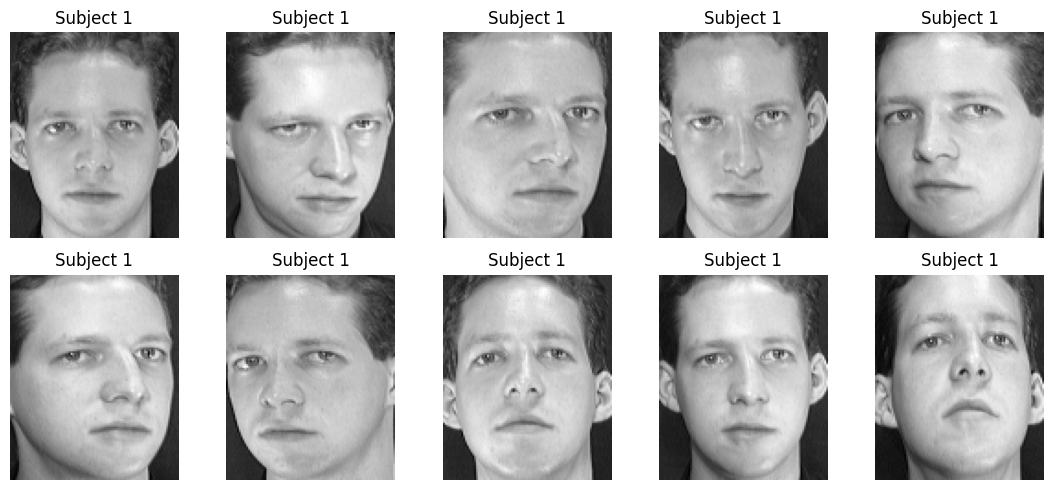

Train: 280 | Test: 120
Subjects in train/test: 40/40


In [3]:
### 3. Sample images and stratified split
fig, axes = plt.subplots(2, 5, figsize=(11, 5))
for i, ax in enumerate(axes.flat):
    ax.imshow(images[i], cmap="gray")
    ax.set_title(f"Subject {y[i]}")
    ax.axis("off")
plt.tight_layout()
plt.show()

# Reproducible stratified split using NumPy (each subject appears in both sets).
rng = np.random.default_rng(42)
train_indices, test_indices = [], []
for subject in np.unique(y):
    subject_indices = np.flatnonzero(y == subject)
    rng.shuffle(subject_indices)
    n_test = max(1, int(round(0.30 * len(subject_indices))))
    test_indices.extend(subject_indices[:n_test])
    train_indices.extend(subject_indices[n_test:])

train_indices = np.asarray(train_indices)
test_indices = np.asarray(test_indices)
rng.shuffle(train_indices)
rng.shuffle(test_indices)

X_train, X_test = X[train_indices], X[test_indices]
y_train, y_test = y[train_indices], y[test_indices]
print(f"Train: {len(X_train)} | Test: {len(X_test)}")
print(f"Subjects in train/test: {len(np.unique(y_train))}/{len(np.unique(y_test))}")


In [4]:
### 4. PCA with NumPy: eigendecomposition and SVD
mean_face = X_train.mean(axis=0)
X_centered = X_train - mean_face

# Sample-space Gram matrix gives the same non-zero principal directions.
gram = X_centered @ X_centered.T
eigvals, eigvecs = np.linalg.eigh(gram)
order = np.argsort(eigvals)[::-1]
eigvals, eigvecs = eigvals[order], eigvecs[:, order]
valid = eigvals > max(eigvals[0] * 1e-12, 1e-12)
eigvals, eigvecs = eigvals[valid], eigvecs[:, valid]
components = (X_centered.T @ eigvecs) / np.sqrt(eigvals)[None, :]
components /= np.linalg.norm(components, axis=0, keepdims=True) + 1e-15

# Independent SVD solution for comparison.
_, singular_values, Vt = np.linalg.svd(X_centered, full_matrices=False)
svd_components = Vt.T
svd_eigenvalues = singular_values ** 2

explained = eigvals / eigvals.sum()
cumulative = np.cumsum(explained)
k90 = int(np.searchsorted(cumulative, 0.90) + 1)
k90 = min(k90, len(cumulative))

compare_k = min(20, components.shape[1], svd_components.shape[1])
agreement = np.abs(np.sum(components[:, :compare_k] * svd_components[:, :compare_k], axis=0))
print(f"Components for >=90% variance: {k90}")
print(f"Variance retained: {100*cumulative[k90-1]:.2f}%")
print(f"Mean absolute eig/SVD direction agreement: {agreement.mean():.6f}")


Components for >=90% variance: 92
Variance retained: 90.05%
Mean absolute eig/SVD direction agreement: 1.000000


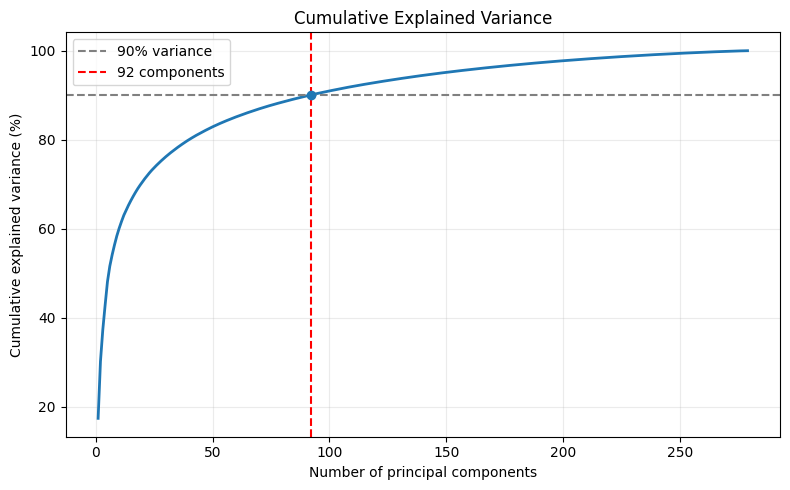

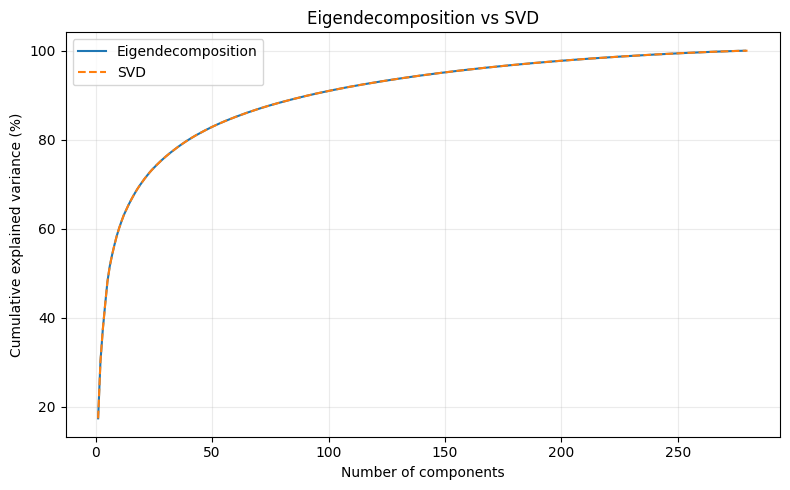

In [5]:
### 5. Explained variance
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cumulative) + 1), cumulative * 100, linewidth=2)
plt.axhline(90, color="gray", linestyle="--", label="90% variance")
plt.axvline(k90, color="red", linestyle="--", label=f"{k90} components")
plt.scatter([k90], [cumulative[k90-1] * 100], zorder=3)
plt.xlabel("Number of principal components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("Cumulative Explained Variance")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()

svd_cumulative = np.cumsum(svd_eigenvalues / svd_eigenvalues.sum())
plt.figure(figsize=(8, 5))
plt.plot(np.arange(1, len(cumulative)+1), cumulative*100, label="Eigendecomposition")
plt.plot(np.arange(1, len(svd_cumulative)+1), svd_cumulative*100, "--", label="SVD")
plt.xlabel("Number of components")
plt.ylabel("Cumulative explained variance (%)")
plt.title("Eigendecomposition vs SVD")
plt.grid(alpha=0.25)
plt.legend()
plt.tight_layout()
plt.show()


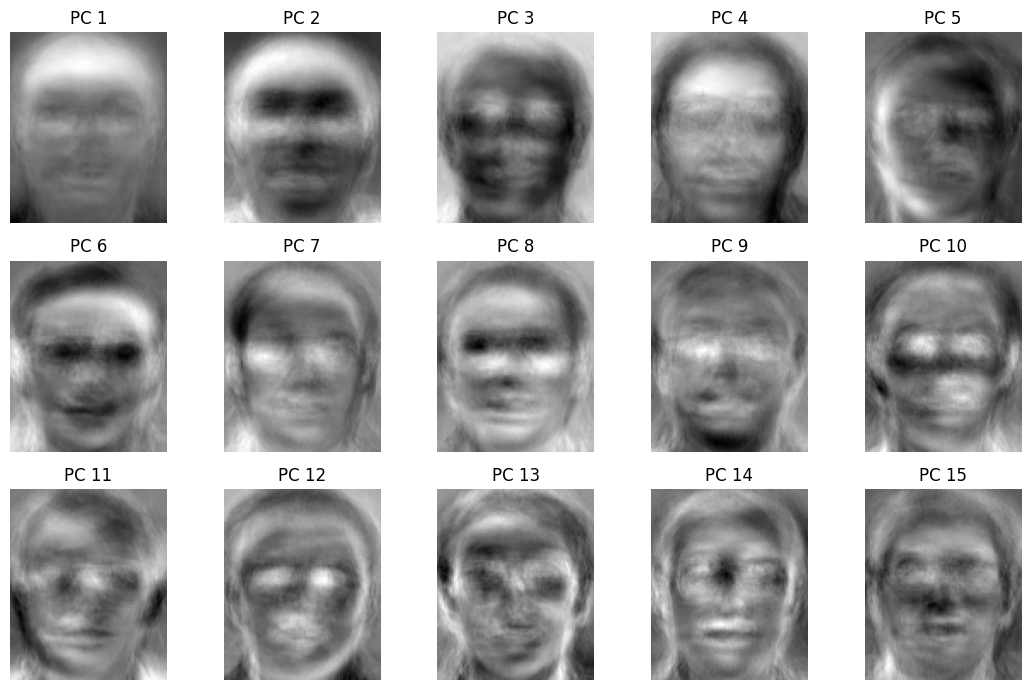

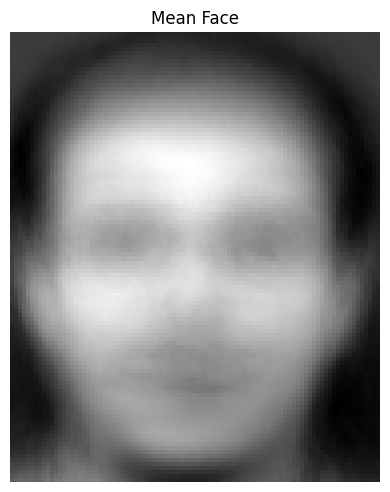

In [6]:
### 6. Mean face and eigenfaces
fig, axes = plt.subplots(3, 5, figsize=(11, 7))
for i, ax in enumerate(axes.flat):
    face = components[:, i].reshape(height, width)
    lo, hi = face.min(), face.max()
    ax.imshow((face-lo)/(hi-lo+1e-12), cmap="gray")
    ax.set_title(f"PC {i+1}")
    ax.axis("off")
plt.tight_layout()
plt.show()

plt.figure(figsize=(4, 5))
plt.imshow(mean_face.reshape(height, width), cmap="gray")
plt.title("Mean Face")
plt.axis("off")
plt.tight_layout()
plt.show()


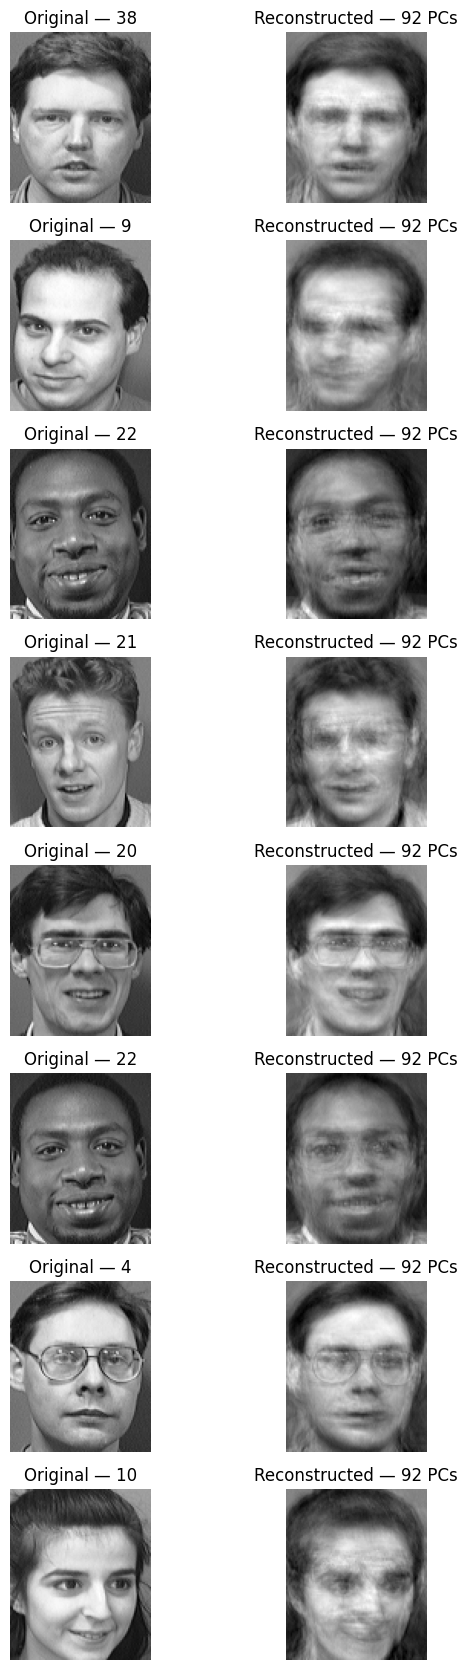

Reconstruction MSE: 315.229
Pixel matrix: 23,080,960 bytes | PCA representation + basis + mean: 7,872,256 bytes
Storage ratio: 2.93x


In [7]:
### 7. Projection, reconstruction and storage
basis = components[:, :k90]
Z_train = (X_train - mean_face) @ basis
Z_test = (X_test - mean_face) @ basis

sample_count = min(8, len(X_test))
Z_sample = Z_test[:sample_count]
reconstructed = Z_sample @ basis.T + mean_face
reconstructed_images = np.clip(reconstructed.reshape(-1, height, width), 0, 255)

fig, axes = plt.subplots(sample_count, 2, figsize=(7, 2.1*sample_count), squeeze=False)
for i in range(sample_count):
    axes[i, 0].imshow(X_test[i].reshape(height, width), cmap="gray")
    axes[i, 0].set_title(f"Original — {y_test[i]}")
    axes[i, 0].axis("off")
    axes[i, 1].imshow(reconstructed_images[i], cmap="gray")
    axes[i, 1].set_title(f"Reconstructed — {k90} PCs")
    axes[i, 1].axis("off")
plt.tight_layout()
plt.show()

reconstruction_mse = np.mean((X_test[:sample_count] - reconstructed) ** 2)
original_bytes = X_train.size * X_train.dtype.itemsize
pca_bytes = Z_train.size * Z_train.dtype.itemsize + basis.size * basis.dtype.itemsize + mean_face.size * mean_face.dtype.itemsize
storage_ratio = original_bytes / pca_bytes
print(f"Reconstruction MSE: {reconstruction_mse:.3f}")
print(f"Pixel matrix: {original_bytes:,} bytes | PCA representation + basis + mean: {pca_bytes:,} bytes")
print(f"Storage ratio: {storage_ratio:.2f}x")


Raw-pixel nearest-neighbor: 97.50%
PCA nearest-neighbor (92 PCs): 96.67%


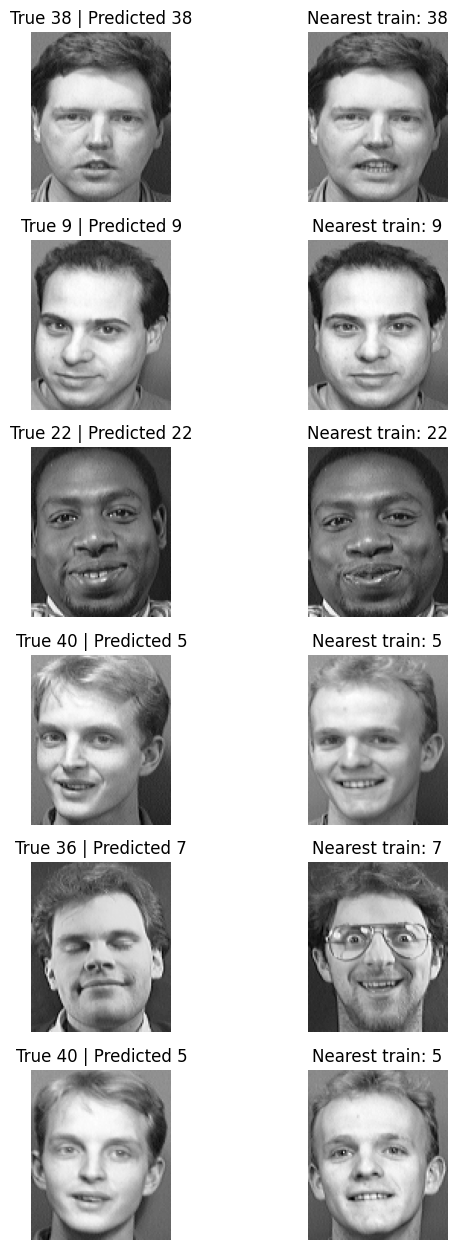

In [8]:
### 8. Nearest-face recognition
def nearest_face(train_features, train_labels, test_features):
    distances = np.sqrt(((test_features[:, None, :] - train_features[None, :, :]) ** 2).sum(axis=2))
    nearest_indices = np.argmin(distances, axis=1)
    return train_labels[nearest_indices], nearest_indices

raw_predictions, raw_matches = nearest_face(X_train, y_train, X_test)
pca_predictions, pca_matches = nearest_face(Z_train, y_train, Z_test)

def accuracy(y_true, y_pred):
    return np.mean(np.asarray(y_true) == np.asarray(y_pred))

raw_accuracy = accuracy(y_test, raw_predictions)
pca_accuracy = accuracy(y_test, pca_predictions)
print(f"Raw-pixel nearest-neighbor: {100*raw_accuracy:.2f}%")
print(f"PCA nearest-neighbor ({k90} PCs): {100*pca_accuracy:.2f}%")

correct = [i for i in range(len(y_test)) if pca_predictions[i] == y_test[i]][:3]
incorrect = [i for i in range(len(y_test)) if pca_predictions[i] != y_test[i]][:3]
selected = correct + incorrect
if selected:
    fig, axes = plt.subplots(len(selected), 2, figsize=(7, 2.1*len(selected)), squeeze=False)
    for row, i in enumerate(selected):
        axes[row, 0].imshow(X_test[i].reshape(height, width), cmap="gray")
        axes[row, 0].set_title(f"True {y_test[i]} | Predicted {pca_predictions[i]}")
        axes[row, 0].axis("off")
        match_i = pca_matches[i]
        axes[row, 1].imshow(X_train[match_i].reshape(height, width), cmap="gray")
        axes[row, 1].set_title(f"Nearest train: {y_train[match_i]}")
        axes[row, 1].axis("off")
    plt.tight_layout()
    plt.show()


,Model,Accuracy (%),Correct,Test images
0,Logistic Regression,98.33,118,120
1,SVM (RBF),98.33,118,120
2,Raw-pixel Nearest Neighbor,97.50,117,120
3,PCA Nearest Neighbor,96.67,116,120
4,"KNN (k=3, distance weights)",96.67,116,120
5,KNN (k=1),96.67,116,120


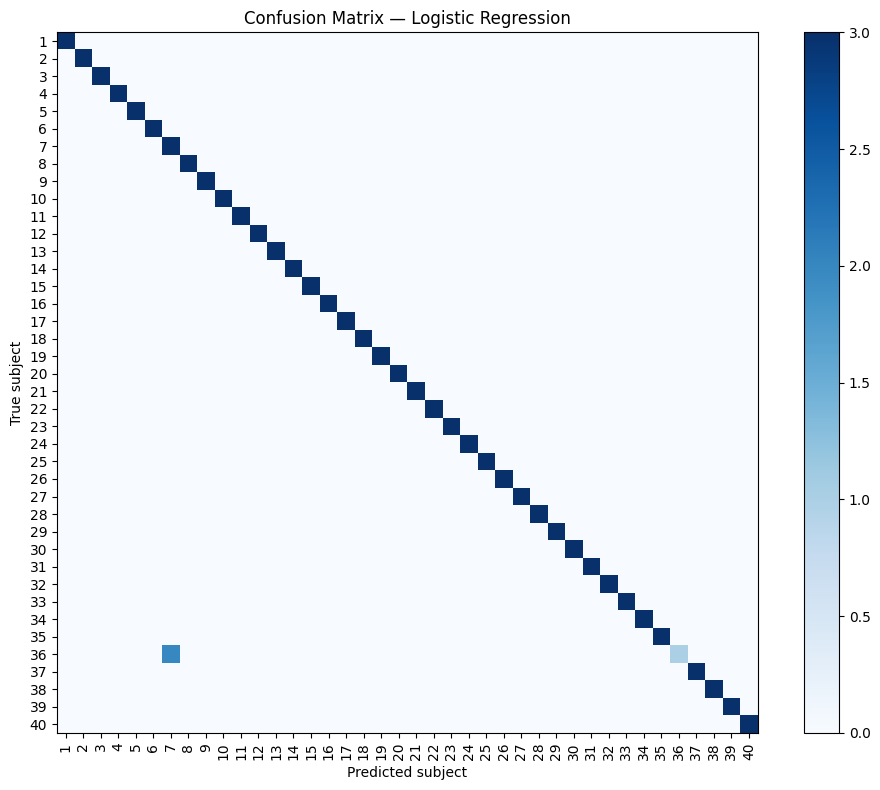

In [9]:
### 9. Traditional ML comparison
models = {
    "PCA Nearest Neighbor": None,
    "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
    "KNN (k=3, distance weights)": KNeighborsClassifier(n_neighbors=3, weights="distance"),
    "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0, random_state=42),
    "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale"),
}
predictions = {"PCA Nearest Neighbor": pca_predictions}
rows = [
    {"Model": "Raw-pixel Nearest Neighbor", "Accuracy (%)": 100*raw_accuracy,
     "Correct": int(np.sum(y_test == raw_predictions)), "Test images": len(y_test)}
]
for name, model in models.items():
    if model is None:
        pred = pca_predictions
    else:
        model.fit(Z_train, y_train)
        pred = model.predict(Z_test)
    predictions[name] = pred
    rows.append({"Model": name, "Accuracy (%)": 100*accuracy(y_test, pred),
                 "Correct": int(np.sum(y_test == pred)), "Test images": len(y_test)})

results = pd.DataFrame(rows).sort_values("Accuracy (%)", ascending=False).reset_index(drop=True)
display(results.style.format({"Accuracy (%)": "{:.2f}"}))

best_name = results.iloc[0]["Model"]
best_predictions = raw_predictions if best_name == "Raw-pixel Nearest Neighbor" else predictions[best_name]
fig, ax = plt.subplots(figsize=(10, 8))
ConfusionMatrixDisplay = None
labels_sorted = np.unique(y)
matrix = np.zeros((len(labels_sorted), len(labels_sorted)), dtype=int)
label_to_index = {label: i for i, label in enumerate(labels_sorted)}
for true_label, pred_label in zip(y_test, best_predictions):
    matrix[label_to_index[true_label], label_to_index[pred_label]] += 1
im = ax.imshow(matrix, cmap="Blues")
ax.set_title(f"Confusion Matrix — {best_name}")
ax.set_xlabel("Predicted subject")
ax.set_ylabel("True subject")
ax.set_xticks(range(len(labels_sorted)), labels_sorted, rotation=90)
ax.set_yticks(range(len(labels_sorted)), labels_sorted)
fig.colorbar(im, ax=ax)
plt.tight_layout()
plt.show()


In [10]:
### 10. Component tuning
component_counts = sorted(set(k for k in [10, 20, 40, 60, 80, 100, k90]
                              if 1 <= k <= components.shape[1]))
tuning_rows = []
for k in component_counts:
    basis_k = components[:, :k]
    z_train_k = (X_train - mean_face) @ basis_k
    z_test_k = (X_test - mean_face) @ basis_k
    tuning_models = {
        "KNN (k=1)": KNeighborsClassifier(n_neighbors=1),
        "KNN (k=3, distance weights)": KNeighborsClassifier(n_neighbors=3, weights="distance"),
        "Logistic Regression": LogisticRegression(max_iter=3000, C=1.0, random_state=42),
        "SVM (RBF)": SVC(kernel="rbf", C=10, gamma="scale"),
    }
    for name, model in tuning_models.items():
        model.fit(z_train_k, y_train)
        tuning_rows.append({"Components": k, "Model": name,
                            "Accuracy (%)": 100*accuracy(y_test, model.predict(z_test_k))})

tuning = pd.DataFrame(tuning_rows)
display(tuning.pivot(index="Components", columns="Model", values="Accuracy (%)").style.format("{:.2f}"))


Model,KNN (k=1),"KNN (k=3, distance weights)",Logistic Regression,SVM (RBF)
Components,,,,
10,94.17,90.83,90.00,95.00
20,96.67,93.33,95.83,97.50
40,96.67,95.00,97.50,98.33
60,96.67,95.83,97.50,98.33
80,96.67,96.67,97.50,98.33
92,96.67,96.67,98.33,98.33
100,96.67,96.67,98.33,98.33


## Final results

The notebook reports the number of components needed to retain at least 90% of training variance, reconstruction error, storage comparison, raw-pixel and PCA nearest-neighbor accuracy, and the traditional-classifier comparison above. The best model is the one with the highest test accuracy in the results table.

PCA is implemented with NumPy (`eigh`, `svd`, matrix operations); Scikit-learn is used only for the traditional classifiers. The train/test split and accuracy calculations are implemented with NumPy.
